# S04 – LIME và SHAP: thực nghiệm trên Breast Cancer Wisconsin

Notebook này đi theo đúng thứ tự: **(0)** cài đặt và chốt quyết định thiết kế → **(1)** dữ liệu, mô hình → **(2)** ví dụ tính tay → **(3)** chọn 3 mẫu theo quy tắc → **(4)** chạy LIME/SHAP → **(5)** biểu đồ đóng góp đặc trưng → **(6)** bảng so sánh LIME vs SHAP → **(7)** độ ổn định + ví dụ giải thích bất ổn → **(8)** kiểm tra faithfulness bằng deletion test.

Cài thư viện (nếu chưa có): `pip install scikit-learn lime shap pandas matplotlib scipy`.

> Ghi chú: mọi con số trong báo cáo phải là số do nhóm tự chạy và ghi lại kèm seed. Các phần nhận xét trong notebook chỉ là gợi ý, hãy kiểm tra lại với kết quả thực tế trước khi dùng.

## 0. Quyết định thiết kế (đưa nguyên vào mục Method của báo cáo)

In [1]:
import time, itertools, warnings, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lime.lime_tabular import LimeTabularExplainer
import shap
warnings.filterwarnings("ignore")
os.makedirs("figs", exist_ok=True); os.makedirs("results", exist_ok=True)

CFG = dict(
    SEED=42,              # random_state cho chia dữ liệu và mô hình
    TEST_SIZE=0.2,
    TARGET=0,             # lớp được giải thích: 0 = malignant (ác tính). Mọi giải thích đều là cho P(malignant)
    BG_SIZE=100,          # số mẫu nền (background) của SHAP
    K=5,                  # top-k dùng để so sánh
    N_LIME_SEEDS=20,      # số seed chạy LIME để đo độ ổn định
    N_SHAP_BG=5,          # số background set khác nhau cho SHAP
    LIME_SAMPLES=5000,    # số điểm nhiễu của LIME
    SHAP_NSAMPLES=2000,   # số coalition mẫu của KernelSHAP
    N_DEL=20,             # số mẫu test dùng cho deletion test
)
globals().update(CFG)
T = TARGET
print(CFG)

ModuleNotFoundError: No module named 'lime'

**Các lựa chọn và lý do (dễ giải thích):**
- Không gian giải thích là **xác suất P(malignant)** (LIME gốc cũng giải thích xác suất). SHAP được tính trên chính hàm xác suất này (KernelSHAP), nên LIME và SHAP so sánh được trực tiếp. Hệ quả: tổng φ cộng tuyến tính trên *xác suất* chứ không phải trên log-odds.
- SHAP dùng **KernelSHAP** cho cả hai mô hình (cùng một công cụ, so sánh runtime công bằng).
- Chọn 3 mẫu bằng quy tắc cố định (mục 3), không chọn tay.
- Top-k: k = 5, thước đo: overlap@k, Jaccard, Spearman trên |đóng góp|.

## 1. Dữ liệu và mô hình

In [ ]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target                 # target: 0 = malignant, 1 = benign
feature_names = list(X.columns); class_names = list(data.target_names)
n_feat = len(feature_names)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
Xtr_np, Xte_np, ytr_np, yte_np = Xtr.values, Xte.values, ytr.values, yte.values
mu_train = Xtr_np.mean(axis=0)

models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=SEED),
}
for m in models.values(): m.fit(Xtr_np, ytr_np)
acc = {n: m.score(Xte_np, yte_np) for n, m in models.items()}
print("Train/test:", Xtr.shape, Xte.shape, "| lớp:", class_names)
print("Accuracy trên test:", acc)

def f_of(model):
    """Hàm cần giải thích: P(malignant) cho mảng numpy."""
    return lambda A: model.predict_proba(np.atleast_2d(A))[:, T]

Train/test: (455, 30) (114, 30) | lớp: [np.str_('malignant'), np.str_('benign')]
Accuracy trên test: {'LogReg': 0.9824561403508771, 'RandomForest': 0.956140350877193}


## 2. Ví dụ tính tay (kiểm chứng + dùng cho báo cáo)

### 2a. SHAP cho mô hình tuyến tính
Mô hình toy: $f(x)=b+\sum_j w_j x_j$, với giá trị trung bình nền $\mu_j=E[X_j]$ và các đặc trưng độc lập. Khi đó $\varphi_j = w_j (x_j-\mu_j)$ và $\varphi_0=f(\mu)=E[f(X)]$. Ta kiểm tra bằng cách liệt kê đủ mọi tập con (công thức Shapley gốc) với hàm giá trị $v(S)=f(x_S,\mu_{\bar S})$.

In [ ]:
w = np.array([2.0, -1.0, 0.5]); b = 1.0
mu = np.array([1.0, 2.0, 4.0]);  x0 = np.array([3.0, 1.0, 6.0])
f_lin = lambda v: b + w @ v
M = len(w)

def v_of(S):                       # giá trị tập con S: đặc trưng trong S lấy từ x0, còn lại lấy trung bình
    z = mu.copy(); z[list(S)] = x0[list(S)]; return f_lin(z)

from math import factorial
phi = np.zeros(M)
for j in range(M):
    others = [i for i in range(M) if i != j]
    for r in range(M):
        for S in itertools.combinations(others, r):
            wgt = factorial(len(S)) * factorial(M - len(S) - 1) / factorial(M)
            phi[j] += wgt * (v_of(S + (j,)) - v_of(S))
phi0 = f_lin(mu)
print("φ0 = f(μ)           :", phi0)
print("φ_j (liệt kê Shapley):", phi)
print("φ_j = w_j(x_j-μ_j)   :", w * (x0 - mu))
print("f(x0)                :", f_lin(x0), "| φ0 + Σφ =", phi0 + phi.sum())
pd.DataFrame({"x_j": x0, "μ_j": mu, "w_j": w, "φ_j": phi})

φ0 = f(μ)           : 3.0
φ_j (liệt kê Shapley): [4. 1. 1.]
φ_j = w_j(x_j-μ_j)   : [4. 1. 1.]
f(x0)                : 9.0 | φ0 + Σφ = 9.0


,x_j,μ_j,w_j,φ_j
0,3.0,1.0,2.0,4.0
1,1.0,2.0,-1.0,1.0
2,6.0,4.0,0.5,1.0


### 2b. LIME từng bước trên mô hình phi tuyến nhỏ
$f(x)=\sigma(x_1^2 - x_2)$ tại $x_0=(1,2)$. Ta tạo 6 điểm nhiễu **cố định** (để dễ theo dõi), tính khoảng cách $D$, trọng số $\pi_{x_0}(z)=\exp(-D^2/\sigma^2)$, rồi giải hồi quy tuyến tính có trọng số (không phạt Ω để đơn giản). Hệ số thu được phải gần đạo hàm thật của $f$ tại $x_0$.

In [ ]:
sig = lambda t: 1 / (1 + np.exp(-t))
f_nl = lambda Z: sig(Z[:, 0] ** 2 - Z[:, 1])
x0n = np.array([1.0, 2.0])
deltas = np.array([[0.3, 0.2], [-0.4, 0.1], [0.2, -0.5], [-0.1, -0.3], [0.5, 0.4], [-0.3, 0.5]])
Z = x0n + deltas
y_z = f_nl(Z)

def lime_by_hand(Z, y_z, sigma):
    D = np.linalg.norm(Z - x0n, axis=1)
    pi = np.exp(-D ** 2 / sigma ** 2)
    A = np.c_[np.ones(len(Z)), Z - x0n]                  # có hệ số chặn; dùng (z - x0) cho dễ đọc
    W = np.diag(pi)
    beta = np.linalg.solve(A.T @ W @ A, A.T @ W @ y_z)   # bình phương tối thiểu có trọng số
    return D, pi, beta

D, pi, beta = lime_by_hand(Z, y_z, sigma=1.0)
print(pd.DataFrame({"z1": Z[:, 0], "z2": Z[:, 1], "f(z)": y_z.round(4), "D": D.round(3), "π": pi.round(3)}))
p0 = f_nl(x0n[None])[0]
print(f"\nf(x0)={p0:.4f}; hệ số LIME (σ=1): g1={beta[1]:.3f}, g2={beta[2]:.3f}")
print(f"Đạo hàm thật: ∂f/∂x1 = {p0*(1-p0)*2*x0n[0]:.3f}, ∂f/∂x2 = {-p0*(1-p0):.3f}")
for s in (0.3, 3.0):
    print(f"σ={s}: g1={lime_by_hand(Z, y_z, s)[2][1]:.3f}, g2={lime_by_hand(Z, y_z, s)[2][2]:.3f}   <- thử đổi σ để xem hệ số có đổi không")

    z1   z2    f(z)      D      π
0  1.3  2.2  0.3752  0.361  0.878
1  0.6  2.1  0.1493  0.412  0.844
2  1.2  1.5  0.4850  0.539  0.748
3  0.9  1.7  0.2911  0.316  0.905
4  1.5  2.4  0.4626  0.640  0.664
5  0.7  2.5  0.1182  0.583  0.712

f(x0)=0.2689; hệ số LIME (σ=1): g1=0.395, g2=-0.149
Đạo hàm thật: ∂f/∂x1 = 0.393, ∂f/∂x2 = -0.197
σ=0.3: g1=0.362, g2=-0.132   <- thử đổi σ để xem hệ số có đổi không
σ=3.0: g1=0.397, g2=-0.150   <- thử đổi σ để xem hệ số có đổi không


## 3. Chọn 3 mẫu theo quy tắc cố định
Quy tắc (viết trước khi xem giải thích): **(i)** ca đúng chắc chắn: dự đoán đúng với độ tin cậy cao nhất của Random Forest (trùng thì lấy chỉ số nhỏ nhất); **(ii)** ca sát ranh giới: |P(malignant) − 0.5| nhỏ nhất; **(iii)** ca dự đoán sai: ca sai đầu tiên của Random Forest (nếu RF không sai ca nào thì dùng LogReg).

In [ ]:
rf, lr = models["RandomForest"], models["LogReg"]
p_rf = f_of(rf)(Xte_np); pred_rf = rf.predict(Xte_np); correct = pred_rf == yte_np
conf = np.maximum(p_rf, 1 - p_rf)
wrong = np.where(~correct)[0]; wrong_src = "RandomForest"
if len(wrong) == 0:
    wrong = np.where(lr.predict(Xte_np) != yte_np)[0]; wrong_src = "LogReg"
i_wrong = int(wrong[0])
i_conf = int(np.where(correct)[0][np.argmax(conf[correct])])
order = [int(i) for i in np.argsort(np.abs(p_rf - 0.5)) if i not in (i_wrong, i_conf)]
i_border = order[0]
INST = {"đúng chắc chắn": i_conf, "sát ranh giới": i_border, "dự đoán sai": i_wrong}
print("Ca sai lấy từ:", wrong_src)
pd.DataFrame([{ "mẫu": k, "chỉ số test": i, "nhãn thật": class_names[yte_np[i]],
               "P(malignant) RF": round(float(f_of(rf)(Xte_np[i])[0]), 3),
               "P(malignant) LR": round(float(f_of(lr)(Xte_np[i])[0]), 3)} for k, i in INST.items()])

Ca sai lấy từ: RandomForest


,mẫu,chỉ số test,nhãn thật,P(malignant) RF,P(malignant) LR
0,đúng chắc chắn,0,malignant,1.000,1.000
1,sát ranh giới,16,benign,0.495,0.634
2,dự đoán sai,3,benign,0.745,0.466


## 4. Chạy LIME và SHAP
Với mỗi (mô hình, mẫu): LIME chạy `N_LIME_SEEDS` seed; SHAP chạy `N_SHAP_BG` background set (mỗi set lấy `BG_SIZE` mẫu ngẫu nhiên từ train với seed khác nhau). **Lần chạy thứ 0 là lần giải thích chính** dùng cho biểu đồ ở mục 5; toàn bộ các lần chạy dùng cho mục 7. Cũng ghi lại thời gian mỗi lần chạy.

Lưu ý khi đọc kết quả: LIME mặc định rời rạc hoá đặc trưng liên tục (theo tứ phân vị của train), nên trọng số LIME là *hiệu ứng của khoảng giá trị mà mẫu rơi vào*; SHAP là đóng góp của giá trị đặc trưng so với nền. Vì vậy ta so sánh chủ yếu **thứ hạng và dấu**, không so độ lớn tuyệt đối.

In [ ]:
def lime_explain(model, x, seed, kernel_width=None, num_samples=LIME_SAMPLES):
    ex = LimeTabularExplainer(Xtr_np, feature_names=feature_names, class_names=class_names,
                              mode="classification", random_state=seed, kernel_width=kernel_width)
    e = ex.explain_instance(x, model.predict_proba, labels=(T,), num_features=n_feat, num_samples=num_samples)
    v = np.zeros(n_feat)
    for i, wt in e.as_map()[T]: v[i] = wt
    return v

def make_bg(size, seed):
    return shap.sample(Xtr_np, size, random_state=seed)

def shap_explain(model, x, bg, seed):
    np.random.seed(seed)
    ex = shap.KernelExplainer(f_of(model), bg)
    sv = np.asarray(ex.shap_values(x.reshape(1, -1), nsamples=SHAP_NSAMPLES, silent=True)).reshape(-1)
    return sv, float(np.ravel(ex.expected_value)[0])

RUNS = {}   # RUNS[model][instance] = dict(lime=(n,30), shap=(n,30), t_lime=[...], t_shap=[...], base=[...])
t0 = time.time()
for mname, model in models.items():
    RUNS[mname] = {}
    for iname, i in INST.items():
        x = Xte_np[i]; r = dict(lime=[], shap=[], t_lime=[], t_shap=[], base=[])
        for s in range(N_LIME_SEEDS):
            t = time.perf_counter(); r["lime"].append(lime_explain(model, x, seed=s)); r["t_lime"].append(time.perf_counter() - t)
        for s in range(N_SHAP_BG):
            bg = make_bg(BG_SIZE, seed=s)
            t = time.perf_counter(); sv, base = shap_explain(model, x, bg, seed=s)
            r["t_shap"].append(time.perf_counter() - t); r["shap"].append(sv); r["base"].append(base)
        for k in ("lime", "shap"): r[k] = np.array(r[k])
        RUNS[mname][iname] = r
    print(mname, "xong,", round(time.time() - t0, 1), "s")

# Kiểm tra tính chất cộng tính của SHAP (local accuracy): φ0 + Σφ ≈ f(x)
rows = []
for mname, model in models.items():
    for iname, i in INST.items():
        r = RUNS[mname][iname]
        rows.append({"mô hình": mname, "mẫu": iname, "f(x)": round(float(f_of(model)(Xte_np[i])[0]), 4),
                     "φ0": round(r["base"][0], 4), "Σφ": round(r["shap"][0].sum(), 4),
                     "φ0+Σφ": round(r["base"][0] + r["shap"][0].sum(), 4)})
pd.DataFrame(rows)

LogReg xong, 4.6 s


RandomForest xong, 19.5 s


,mô hình,mẫu,f(x),φ0,Σφ,φ0+Σφ
0,LogReg,đúng chắc chắn,1.0000,0.3391,0.6609,1.0000
1,LogReg,sát ranh giới,0.6341,0.3391,0.2950,0.6341
2,LogReg,dự đoán sai,0.4665,0.3391,0.1274,0.4665
3,RandomForest,đúng chắc chắn,1.0000,0.3264,0.6736,1.0000
4,RandomForest,sát ranh giới,0.4950,0.3264,0.1686,0.4950
5,RandomForest,dự đoán sai,0.7450,0.3264,0.4186,0.7450


## 5. Biểu đồ đóng góp đặc trưng (output bắt buộc)
Màu cam: đẩy P(malignant) **lên**; màu xanh: kéo **xuống**. Hiển thị 8 đặc trưng có |đóng góp| lớn nhất của lần chạy chính.

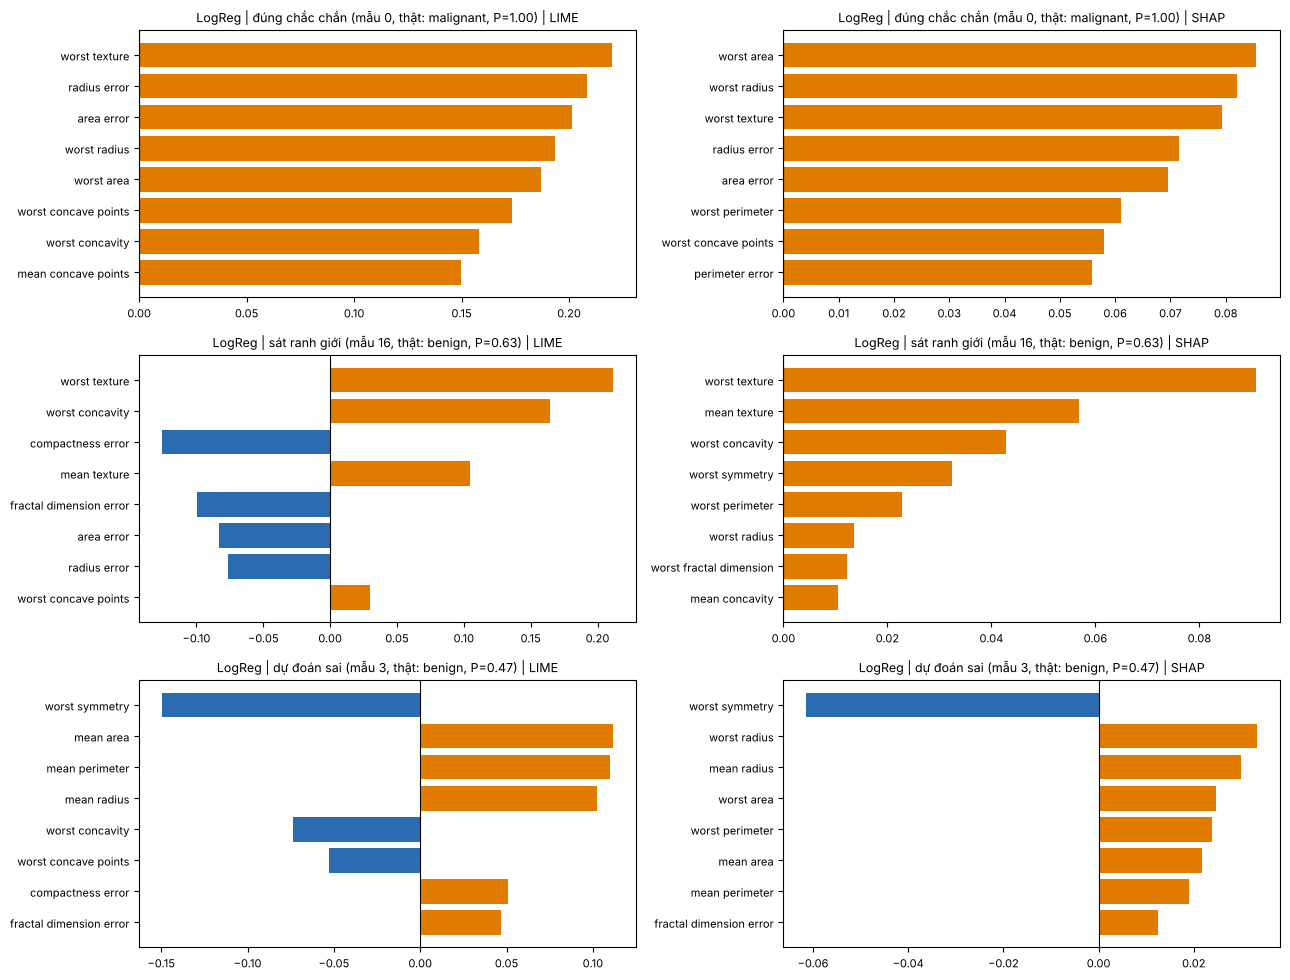

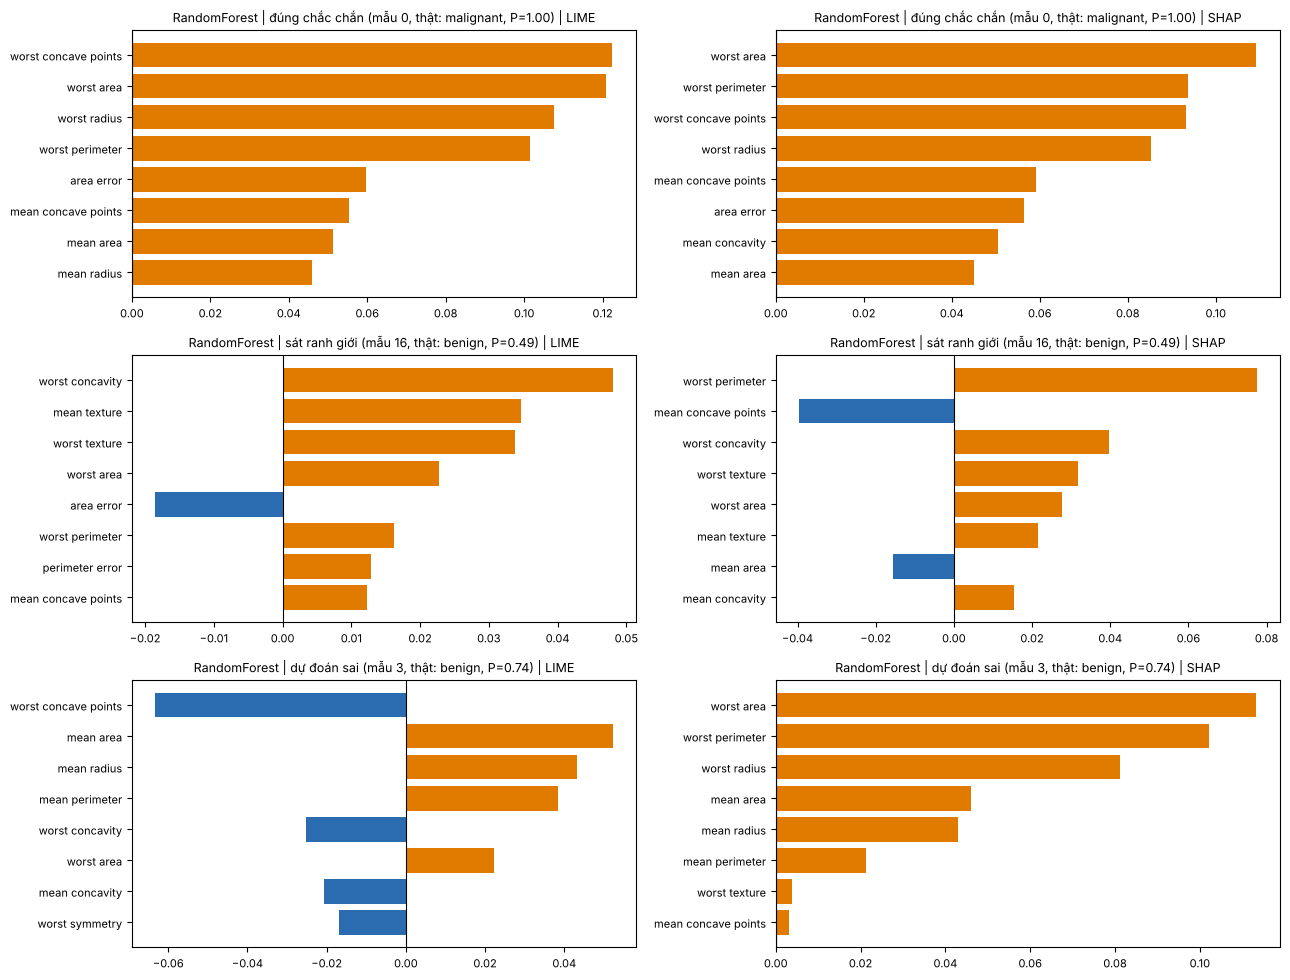

In [ ]:
def plot_contrib(mname, top=8):
    fig, axes = plt.subplots(len(INST), 2, figsize=(13, 3.3 * len(INST)))
    for r_i, (iname, i) in enumerate(INST.items()):
        for c_i, meth in enumerate(("lime", "shap")):
            v = RUNS[mname][iname][meth][0]
            idx = np.argsort(-np.abs(v))[:top][::-1]
            ax = axes[r_i, c_i]
            ax.barh([feature_names[j] for j in idx], v[idx], color=["#e07b00" if a > 0 else "#2b6cb0" for a in v[idx]])
            ax.axvline(0, color="k", lw=0.8)
            p = float(f_of(models[mname])(Xte_np[i])[0])
            ax.set_title(f"{mname} | {iname} (mẫu {i}, thật: {class_names[yte_np[i]]}, P={p:.2f}) | {meth.upper()}", fontsize=9)
            ax.tick_params(labelsize=8)
    plt.tight_layout(); plt.savefig(f"figs/contrib_{mname}.png", dpi=150); plt.show()
for m in models: plot_contrib(m)

## 6. Bảng so sánh LIME vs SHAP
- **overlap@k (lần chạy chính)**: số đặc trưng chung trong top-k của LIME và SHAP chia cho k.
- **overlap@k (trung bình mọi cặp)**: trung bình trên tất cả cặp (lần chạy LIME, lần chạy SHAP).
- **Spearman**: tương quan hạng của |đóng góp| trên cả 30 đặc trưng (lần chạy chính).
- **Đồng dấu**: tỉ lệ đặc trưng chung trong top-k có cùng dấu.
- **Runtime**: trung bình mỗi lần giải thích một mẫu (giây).

In [ ]:
def topk(v, k=K): return set(np.argsort(-np.abs(v))[:k])
rows = []
for mname in models:
    for iname in INST:
        r = RUNS[mname][iname]; L0, S0 = r["lime"][0], r["shap"][0]
        common = topk(L0) & topk(S0)
        pair = np.mean([len(topk(a) & topk(b)) / K for a in r["lime"] for b in r["shap"]])
        rows.append({"mô hình": mname, "mẫu": iname,
                     "overlap@k (chính)": len(common) / K, "overlap@k (TB cặp)": round(pair, 2),
                     "Spearman": round(spearmanr(np.abs(L0), np.abs(S0))[0], 2),
                     "đồng dấu": round(np.mean([np.sign(L0[j]) == np.sign(S0[j]) for j in common]), 2) if common else np.nan,
                     "top-1 LIME": feature_names[int(np.argmax(np.abs(L0)))],
                     "top-1 SHAP": feature_names[int(np.argmax(np.abs(S0)))],
                     "runtime LIME (s)": round(np.mean(r["t_lime"]), 3), "runtime SHAP (s)": round(np.mean(r["t_shap"]), 3)})
CMP = pd.DataFrame(rows); CMP.to_csv("results/compare_lime_shap.csv", index=False); CMP

,mô hình,mẫu,overlap@k (chính),overlap@k (TB cặp),Spearman,đồng dấu,top-1 LIME,top-1 SHAP,runtime LIME (s),runtime SHAP (s)
0,LogReg,đúng chắc chắn,1.0,0.80,0.74,1.0,worst texture,worst area,0.053,0.089
1,LogReg,sát ranh giới,0.6,0.67,0.24,1.0,worst texture,worst texture,0.057,0.092
2,LogReg,dự đoán sai,0.4,0.49,0.26,1.0,worst symmetry,worst symmetry,0.052,0.084
3,RandomForest,đúng chắc chắn,0.8,0.82,0.83,1.0,worst concave points,worst area,0.105,0.585
4,RandomForest,sát ranh giới,0.6,0.71,0.69,1.0,worst concavity,worst perimeter,0.105,0.645
5,RandomForest,dự đoán sai,0.4,0.44,0.46,1.0,worst concave points,worst area,0.096,0.533


## 7. Độ ổn định và ví dụ giải thích bất ổn
**Jaccard trung bình**: với các lần chạy khác seed (LIME) hoặc khác background (SHAP), tính độ giống nhau của top-k giữa mọi cặp lần chạy rồi lấy trung bình (1 = hoàn toàn ổn định). **Tỉ lệ top-1 chiếm ưu thế**: tỉ lệ lần chạy trong đó đặc trưng top-1 là đặc trưng xuất hiện nhiều nhất ở vị trí top-1.

In [ ]:
def mean_jaccard(M):
    sets = [topk(r) for r in M]
    return float(np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(sets, 2)]))
def top1_dominance(M):
    t1 = [int(np.argmax(np.abs(r))) for r in M]
    return max(t1.count(j) for j in set(t1)) / len(t1)

rows = []
for mname in models:
    for iname in INST:
        r = RUNS[mname][iname]
        rows.append({"mô hình": mname, "mẫu": iname,
                     "Jaccard LIME": round(mean_jaccard(r["lime"]), 2), "top-1 chiếm ưu thế LIME": round(top1_dominance(r["lime"]), 2),
                     "Jaccard SHAP": round(mean_jaccard(r["shap"]), 2), "top-1 chiếm ưu thế SHAP": round(top1_dominance(r["shap"]), 2)})
STAB = pd.DataFrame(rows); STAB.to_csv("results/stability.csv", index=False); STAB

,mô hình,mẫu,Jaccard LIME,top-1 chiếm ưu thế LIME,Jaccard SHAP,top-1 chiếm ưu thế SHAP
0,LogReg,đúng chắc chắn,0.78,0.95,0.68,0.4
1,LogReg,sát ranh giới,0.84,1.00,0.73,1.0
2,LogReg,dự đoán sai,0.85,1.00,0.53,1.0
3,RandomForest,đúng chắc chắn,0.94,0.60,1.00,1.0
4,RandomForest,sát ranh giới,0.72,0.80,0.73,1.0
5,RandomForest,dự đoán sai,0.74,1.00,1.00,1.0


Trường hợp bất ổn nhất của LIME: RandomForest | sát ranh giới | Jaccard = 0.72

Top-5 của LIME qua 6 seed đầu:
  seed 0: ['worst concavity', 'mean texture', 'worst texture', 'worst area', 'area error']
  seed 1: ['worst texture', 'worst concavity', 'mean texture', 'worst perimeter', 'worst smoothness']
  seed 2: ['worst texture', 'worst concavity', 'mean texture', 'worst perimeter', 'mean concave points']
  seed 3: ['worst texture', 'worst concavity', 'worst perimeter', 'mean texture', 'worst smoothness']
  seed 4: ['worst texture', 'mean texture', 'worst concavity', 'worst perimeter', 'area error']
  seed 5: ['worst texture', 'worst concavity', 'mean texture', 'worst perimeter', 'radius error']

Top-5 của SHAP qua 5 background:
  bg 0: ['worst perimeter', 'mean concave points', 'worst concavity', 'worst texture', 'worst area']
  bg 1: ['worst perimeter', 'mean concave points', 'worst concavity', 'worst texture', 'mean texture']
  bg 2: ['worst perimeter', 'worst concavity', 'mean conc

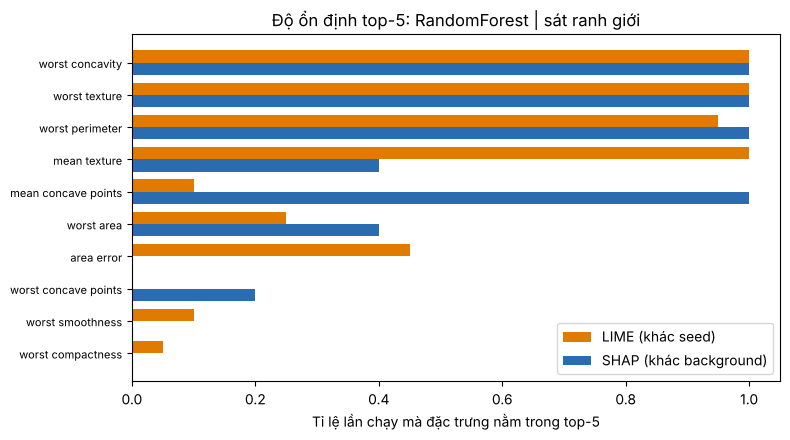

In [ ]:
# Ví dụ bất ổn: chọn (mô hình, mẫu) có Jaccard LIME thấp nhất
worst = STAB.sort_values("Jaccard LIME").iloc[0]
wm, wi = worst["mô hình"], worst["mẫu"]
print("Trường hợp bất ổn nhất của LIME:", wm, "|", wi, "| Jaccard =", worst["Jaccard LIME"])
r = RUNS[wm][wi]
print("\nTop-%d của LIME qua 6 seed đầu:" % K)
for s in range(6): print(f"  seed {s}:", [feature_names[j] for j in np.argsort(-np.abs(r['lime'][s]))[:K]])
print("\nTop-%d của SHAP qua %d background:" % (K, N_SHAP_BG))
for s in range(N_SHAP_BG): print(f"  bg {s}:", [feature_names[j] for j in np.argsort(-np.abs(r['shap'][s]))[:K]])

freq = lambda M: np.array([sum(j in topk(row) for row in M) / len(M) for j in range(n_feat)])
fl, fs = freq(r["lime"]), freq(r["shap"])
idx = np.argsort(-(fl + fs))[:10][::-1]
fig, ax = plt.subplots(figsize=(8, 4.5)); h = 0.38; yy = np.arange(len(idx))
ax.barh(yy + h / 2, fl[idx], h, label="LIME (khác seed)", color="#e07b00")
ax.barh(yy - h / 2, fs[idx], h, label="SHAP (khác background)", color="#2b6cb0")
ax.set_yticks(yy); ax.set_yticklabels([feature_names[j] for j in idx], fontsize=8)
ax.set_xlabel(f"Tỉ lệ lần chạy mà đặc trưng nằm trong top-{K}"); ax.legend(); ax.set_title(f"Độ ổn định top-{K}: {wm} | {wi}")
plt.tight_layout(); plt.savefig("figs/unstable_example.png", dpi=150); plt.show()

### 7b. Độ nhạy theo kích thước background (SHAP) và kernel width (LIME) – mẫu sát ranh giới của Random Forest

In [ ]:
i = INST["sát ranh giới"]; x = Xte_np[i]; rows = []
for size in (10, 50, 100):
    M = np.array([shap_explain(rf, x, make_bg(size, s), s)[0] for s in range(N_SHAP_BG)])
    rows.append({"phương pháp": "SHAP", "tham số": f"background={size}", "Jaccard top-k": round(mean_jaccard(M), 2), "top-1 chiếm ưu thế": round(top1_dominance(M), 2)})
for kw in (1.0, 2.0, 0.75 * np.sqrt(n_feat), 8.0):
    M = np.array([lime_explain(rf, x, s, kernel_width=kw) for s in range(10)])
    rows.append({"phương pháp": "LIME", "tham số": f"kernel_width={kw:.2f}", "Jaccard top-k": round(mean_jaccard(M), 2), "top-1 chiếm ưu thế": round(top1_dominance(M), 2)})
SENS = pd.DataFrame(rows); SENS.to_csv("results/sensitivity.csv", index=False); SENS

,phương pháp,tham số,Jaccard top-k,top-1 chiếm ưu thế
0,SHAP,background=10,0.63,0.8
1,SHAP,background=50,0.73,1.0
2,SHAP,background=100,0.73,1.0
3,LIME,kernel_width=1.00,0.65,0.7
4,LIME,kernel_width=2.00,0.68,0.9
5,LIME,kernel_width=4.11,0.68,0.9
6,LIME,kernel_width=8.00,0.68,0.9


## 8. Kiểm tra faithfulness bằng deletion test
Ý tưởng: lần lượt "xoá" các đặc trưng được giải thích xếp cao nhất (thay bằng trung bình train) và theo dõi xác suất của lớp được dự đoán. Nếu giải thích trung thành, xác suất phải giảm **nhanh hơn** so với xoá ngẫu nhiên. Chạy trên `N_DEL` mẫu test ngẫu nhiên (seed cố định), cả hai mô hình.

Hạn chế cần nêu trong báo cáo: thay bằng trung bình có thể tạo điểm ngoài phân phối dữ liệu, và các đặc trưng ở đây tương quan mạnh nên xoá từng đặc trưng chưa phản ánh hết tác động.

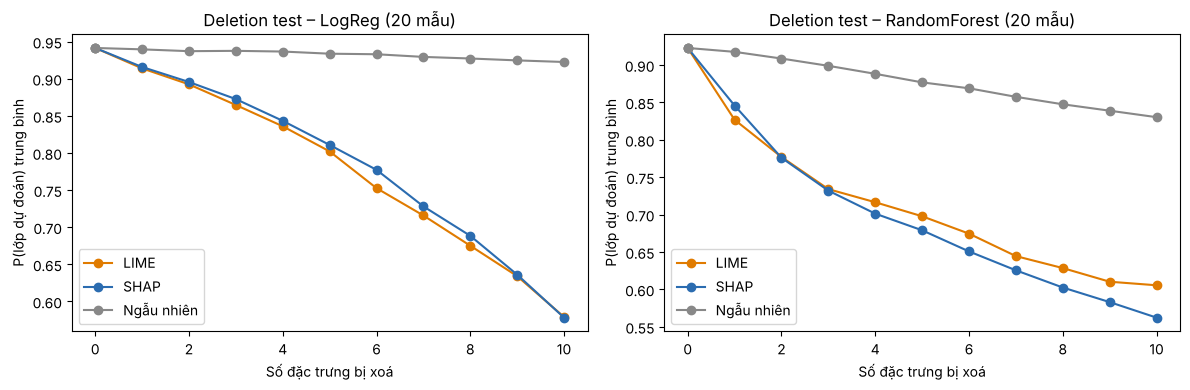

,0,1,3,5,10
LogReg|LIME,0.941,0.914,0.865,0.802,0.579
LogReg|SHAP,0.941,0.916,0.873,0.811,0.578
LogReg|Ngẫu nhiên,0.941,0.940,0.938,0.934,0.923
RandomForest|LIME,0.923,0.827,0.734,0.698,0.605
RandomForest|SHAP,0.923,0.846,0.732,0.679,0.562
RandomForest|Ngẫu nhiên,0.923,0.918,0.899,0.877,0.830


In [ ]:
rng = np.random.RandomState(SEED)
del_idx = rng.choice(len(Xte_np), N_DEL, replace=False)
MAXM = 10

def curve(model, x, order, c):
    out = []
    for m in range(MAXM + 1):
        z = x.copy(); z[order[:m]] = mu_train[order[:m]]
        out.append(model.predict_proba(z[None])[0, c])
    return np.array(out)

bg0 = make_bg(BG_SIZE, 0); fig, axes = plt.subplots(1, 2, figsize=(12, 4)); DEL = {}
for ax, (mname, model) in zip(axes, models.items()):
    cur = {"LIME": [], "SHAP": [], "Ngẫu nhiên": []}
    for i in del_idx:
        x = Xte_np[i]; c = int(model.predict(x[None])[0]); sgn = 1 if c == T else -1   # đóng góp theo hướng lớp được dự đoán
        for name, v in (("LIME", lime_explain(model, x, 0)), ("SHAP", shap_explain(model, x, bg0, 0)[0])):
            cur[name].append(curve(model, x, np.argsort(-(sgn * v)), c))
        cur["Ngẫu nhiên"].append(np.mean([curve(model, x, rng.permutation(n_feat), c) for _ in range(10)], axis=0))
    for name, col in (("LIME", "#e07b00"), ("SHAP", "#2b6cb0"), ("Ngẫu nhiên", "#888888")):
        m_ = np.mean(cur[name], axis=0); DEL[(mname, name)] = m_
        ax.plot(range(MAXM + 1), m_, marker="o", label=name, color=col)
    ax.set_title(f"Deletion test – {mname} ({N_DEL} mẫu)"); ax.set_xlabel("Số đặc trưng bị xoá"); ax.set_ylabel("P(lớp dự đoán) trung bình"); ax.legend()
plt.tight_layout(); plt.savefig("figs/deletion_test.png", dpi=150); plt.show()
pd.DataFrame({f"{k[0]}|{k[1]}": v for k, v in DEL.items()}).round(3).to_csv("results/deletion_curves.csv")
pd.DataFrame({f"{k[0]}|{k[1]}": v.round(3) for k, v in DEL.items()}).T[[0, 1, 3, 5, 10]]

## 9. Checklist chuyển vào báo cáo
1. Mục Method: dán lại ô cấu hình `CFG` + giải thích lý do chọn (đặc biệt không gian xác suất).
2. Ví dụ tính tay: mục 2a (SHAP) và 2b (LIME) — định nghĩa mọi ký hiệu, nêu giả định độc lập đặc trưng.
3. Hình bắt buộc: `figs/contrib_*.png`, bảng so sánh `results/compare_lime_shap.csv`, ví dụ bất ổn `figs/unstable_example.png`.
4. Phần thảo luận: nhận xét **dựa trên số liệu của nhóm**, nêu rõ giới hạn (một dataset, ba mẫu, ít mô hình), không kết luận quá mức.
5. Phân biệt rõ kết quả trong paper gốc với kết quả nhóm tự chạy; ghi nguồn thư viện (`lime`, `shap`, `scikit-learn`) và công cụ AI đã dùng.